# 15 · La ruina del jugador

Una caminata aleatoria con dos barreras absorbentes: la probabilidad de ganar, la duración del juego y por qué una ligera desventaja es decisiva a largo plazo.

## El problema

Dos jugadores $A$ y $B$ apuestan un peso en cada lanzamiento de una moneda: $A$ gana con probabilidad $p\in(0,1)$ y $B$ con probabilidad $q=1-p$. Los lanzamientos son independientes y el juego termina cuando alguno se queda sin dinero.

Si $A$ empieza con $n$ pesos y $B$ con $N-n$, ¿cuál es la probabilidad de que $A$ gane?

## Solución analítica

Sea $A_n=\mathbb P(A\text{ gana empezando con }n\text{ pesos})$. Entonces $A_0=0$ y $A_N=1$. Para $0<n<N$, condicionando en el resultado del siguiente lanzamiento (ley de probabilidad total),

$$A_n=p\,A_{n+1}+q\,A_{n-1}.$$

Como $p+q=1$, esto equivale a $p(A_{n+1}-A_n)=q(A_n-A_{n-1})$, es decir,

$$A_{n+1}-A_n=\frac qp\,(A_n-A_{n-1}).$$

Iterando desde $A_0=0$ se obtiene $A_{k}-A_{k-1}=\left(\frac qp\right)^{k-1}A_1$, y sumando para $k=1,\dots,n$:

$$A_n=A_1\sum_{k=0}^{n-1}\left(\frac qp\right)^k=\begin{cases}\dfrac{1-(q/p)^n}{1-q/p}\,A_1,& p\neq q,\\[0.8em] n\,A_1,& p=q.\end{cases}$$

La condición $A_N=1$ determina $A_1$ y da

$$A_n=\begin{cases}\dfrac{1-(q/p)^n}{1-(q/p)^N},& p\neq q,\\[0.8em] \dfrac nN,& p=q=\tfrac12.\end{cases}$$

## La duración del juego

Sea $\tau$ el número de lanzamientos hasta que el juego termina y $T_n=\mathbb E[\tau]$ cuando $A$ empieza con $n$. Por el mismo argumento, $T_0=T_N=0$ y $T_n=1+pT_{n+1}+qT_{n-1}$, de donde

$$T_n=\begin{cases}\dfrac{n}{q-p}-\dfrac{N}{q-p}\cdot\dfrac{1-(q/p)^n}{1-(q/p)^N},& p\neq q,\\[0.8em] n(N-n),& p=q.\end{cases}$$

In [1]:
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(2026)


def prob_ganar(n, N, p):
    """Probabilidad de que A llegue a N antes que a 0, empezando en n."""
    if p == 0.5:
        return n / N
    r = (1 - p) / p
    return (1 - r**n) / (1 - r**N)


def duracion_esperada(n, N, p):
    if p == 0.5:
        return n * (N - n)
    q = 1 - p
    return n / (q - p) - N / (q - p) * prob_ganar(n, N, p)

## Simulación

`juego_ruina` devuelve la trayectoria de la fortuna de $A$ hasta la absorción en $0$ o en $N$.

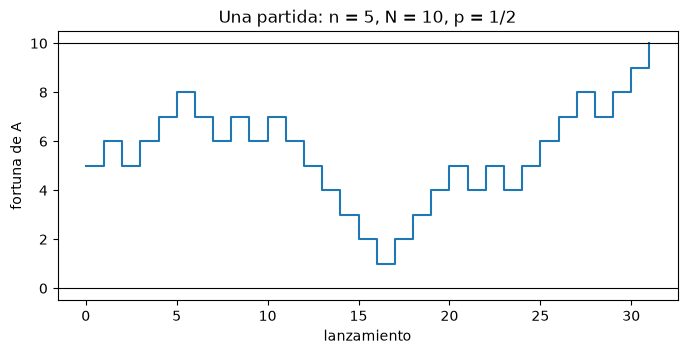

In [2]:
def juego_ruina(n, N, p):
    """Trayectoria de la fortuna de A, desde n hasta llegar a 0 o a N."""
    trayectoria = [n]
    while 0 < trayectoria[-1] < N:
        trayectoria.append(trayectoria[-1] + (1 if rng.random() < p else -1))
    return np.array(trayectoria)


tray = juego_ruina(5, 10, 0.5)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.step(np.arange(len(tray)), tray, where="post")
ax.axhline(0, color="k", lw=0.8)
ax.axhline(10, color="k", lw=0.8)
ax.set_title("Una partida: n = 5, N = 10, p = 1/2")
ax.set_xlabel("lanzamiento")
ax.set_ylabel("fortuna de A")
plt.show()

Para estimar la probabilidad de ruina de $A$ repetimos el juego $M$ veces y contamos en cuántas $A$ termina en $0$. La estimación debe aproximar $1-A_n$.

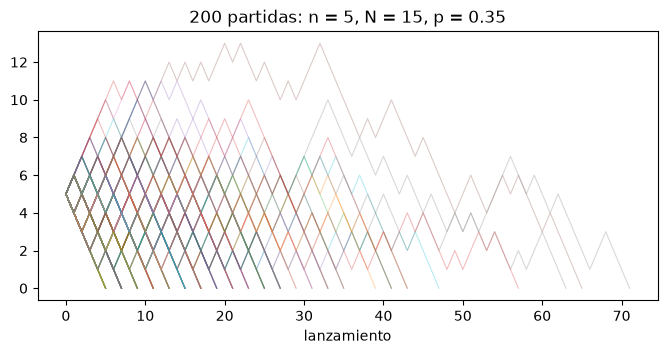

probabilidad de ruina teórica:  0.9980
probabilidad de ruina empírica: 0.9985
duración esperada teórica:  16.569
duración promedio empírica: 16.968


In [3]:
n, N, p, M = 5, 15, 0.35, 2000

partidas = [juego_ruina(n, N, p) for _ in range(M)]
finales = np.array([t[-1] for t in partidas])
duraciones = np.array([len(t) - 1 for t in partidas])

fig, ax = plt.subplots(figsize=(8, 3.5))
for t in partidas[:200]:
    ax.plot(t, alpha=0.3, lw=0.8)
ax.set_title(f"200 partidas: n = {n}, N = {N}, p = {p}")
ax.set_xlabel("lanzamiento")
plt.show()

print(f"probabilidad de ruina teórica:  {1 - prob_ganar(n, N, p):.4f}")
print(f"probabilidad de ruina empírica: {np.mean(finales == 0):.4f}")
print(f"duración esperada teórica:  {duracion_esperada(n, N, p):.3f}")
print(f"duración promedio empírica: {duraciones.mean():.3f}")

## Simulación vectorizada

Para muchas partidas largas conviene simularlas todas a la vez: en cada paso se mueven solo las partidas que siguen activas.

In [4]:
def ruina_vectorizada(n, N, p, M):
    """Devuelve (fortuna final, duración) de M partidas independientes."""
    x = np.full(M, n)
    duracion = np.zeros(M, dtype=int)
    activas = np.ones(M, dtype=bool)
    while activas.any():
        k = activas.sum()
        x[activas] += np.where(rng.random(k) < p, 1, -1)
        duracion[activas] += 1
        activas &= (x > 0) & (x < N)
    return x, duracion

finales, duraciones = ruina_vectorizada(5, 15, 0.35, 100_000)
print(f"ruina empírica con 100 000 partidas: {np.mean(finales == 0):.4f}   duración: {duraciones.mean():.3f}")

ruina empírica con 100 000 partidas: 0.9979   duración: 16.573


## El sentido común y una moneda casi justa

Simular permite experimentar con los parámetros. Supongamos que el juego es parte de un casino y es casi justo: $p=0.49$. Un jugador sigue la «estrategia» de retirarse en cuanto duplique su dinero: empieza con $50$ pesos y se retira al llegar a $100$. ¿Con qué probabilidad lo logra?

In [5]:
for p in [0.5, 0.49]:
    finales, duraciones = ruina_vectorizada(50, 100, p, 5000)
    print(f"p = {p}:  P(duplicar) teórica = {prob_ganar(50, 100, p):.4f}, empírica = {np.mean(finales == 100):.4f};"
          f"  duración media = {duraciones.mean():.0f} (teórica {duracion_esperada(50, 100, p):.0f})")

p = 0.5:  P(duplicar) teórica = 0.5000, empírica = 0.4994;  duración media = 2511 (teórica 2500)


p = 0.49:  P(duplicar) teórica = 0.1192, empírica = 0.1222;  duración media = 1894 (teórica 1904)


La misma comparación, interactiva (Altair): elige $p$ y observa $A_n$ para $N=100$.

In [6]:
import altair as alt
import pandas as pd

ps = [0.45, 0.47, 0.48, 0.49, 0.495, 0.5, 0.505, 0.51, 0.52, 0.55]
datos = pd.DataFrame([{"p": p, "n": n, "A_n": prob_ganar(n, 100, p)} for p in ps for n in range(101)])
p_sel = alt.param(name="p", value=0.49, bind=alt.binding_select(options=ps, name="p: "))
alt.Chart(datos).mark_line().encode(
    x=alt.X("n:Q", title="capital inicial n"),
    y=alt.Y("A_n:Q", title="P(llegar a 100)", scale=alt.Scale(domain=[0, 1])),
    tooltip=["n", alt.Tooltip("A_n:Q", format=".4f")],
).transform_filter(alt.datum.p == p_sel).add_params(p_sel).properties(width=480, height=240)

alt.Chart(...)

Una desventaja de un punto porcentual por apuesta reduce la probabilidad de duplicar de $1/2$ a cerca de $0.12$. La razón es que el exponente $N$ en $(q/p)^N$ amplifica el sesgo: para $N$ grande, $A_n\approx(p/q)^{N-n}$.

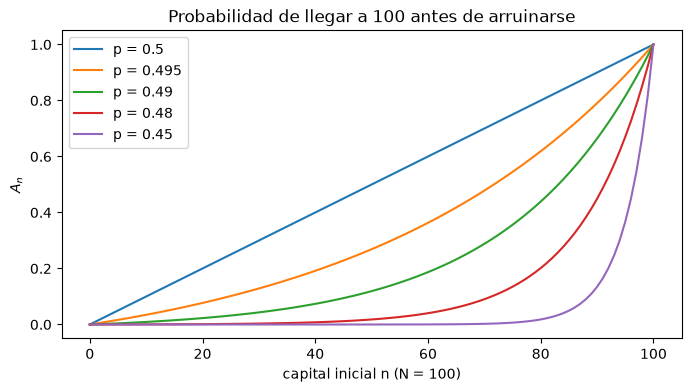

In [7]:
n_valores = np.arange(0, 101)
fig, ax = plt.subplots(figsize=(8, 4))
for p in [0.5, 0.495, 0.49, 0.48, 0.45]:
    ax.plot(n_valores, [prob_ganar(n, 100, p) for n in n_valores], label=f"p = {p}")
ax.set_xlabel("capital inicial n (N = 100)")
ax.set_ylabel("$A_n$")
ax.set_title("Probabilidad de llegar a 100 antes de arruinarse")
ax.legend()
plt.show()

## Ejercicios

1. Verifica numéricamente que $T_n$ satisface la ecuación en diferencias $T_n=1+pT_{n+1}+qT_{n-1}$.
2. Con $p=\frac12$, demuestra que $\mathbb E[\tau]=n(N-n)$ y compáralo con la simulación para $n=50$, $N=100$.
3. Si $B$ tiene fortuna infinita ($N\to\infty$), ¿cuál es la probabilidad de que $A$ se arruine cuando $p>\frac12$? ¿Y cuando $p\le\frac12$?